Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


In [2]:
import os
# Ogranicz BLAS do 1 wątku per proces, żeby implicit (num_threads=2)
# i Optuna (n_jobs=6) nie powodowały oversubscription na 7800X3D.
# Musi być ustawione PRZED importem numpy/implicit.
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import pandas as pd
import implicit
import numpy as np
print(implicit.__version__)
import optuna

from optuna.samplers import TPESampler
from optuna.pruners import HyperbandPruner
from optuna.storages import RDBStorage


0.7.2


## random per user split

In [3]:
from steam_recommender.splitting import random_user_split_train_val


## import danych

In [4]:
base_path = str(project_path("data/processed"))

cold_start_users = pd.read_csv(str(Path(base_path) / "cold_start_users.csv"))
test_df = pd.read_csv(str(Path(base_path) / "users_items_filtered_test.csv"))
train_val_df = pd.read_csv(str(Path(base_path) / "users_items_filtered_train_val.csv"))
full_df = pd.read_csv(str(Path(base_path) / "users_items_filtered.csv"))

print("cold_start_users:", cold_start_users.shape)
print("test_df:", test_df.shape)
print("train_val_df:", train_val_df.shape)
print("full_df:", full_df.shape)

C:\Users\misie\AppData\Local\Temp\ipykernel_19872\4177324918.py:5: DtypeWarning: Columns (0: user_id) have mixed types. Specify dtype option on import or set low_memory=False.
  train_val_df = pd.read_csv(base_path + r"\users_items_filtered_train_val.csv")


cold_start_users: (16902, 4)
test_df: (541231, 4)
train_val_df: (4591379, 4)
full_df: (5132610, 4)


In [5]:
# Clean up data types
full_df = full_df.copy()

full_df["user_id"] = full_df["user_id"].astype(str)
full_df["item_id"] = full_df["item_id"].astype(str)

train_val_df["user_id"] = train_val_df["user_id"].astype(str)
train_val_df["item_id"] = train_val_df["item_id"].astype(str)

test_df["user_id"] = test_df["user_id"].astype(str)
test_df["item_id"] = test_df["item_id"].astype(str)

cold_start_users["user_id"] = cold_start_users["user_id"].astype(str)

## pipeline implicit ALS

In [6]:
from steam_recommender.tuning_als import ALSPipeline


## dalsza czesc z optuna

In [8]:

# =========================
# SIGNAL FUNCTION
# =========================

from steam_recommender.confidence import linear_signal


# =========================
# TRAIN / VAL SPLIT
# =========================

train_df, val_df = random_user_split_train_val(
    train_val_df,
    val_frac=0.1,
    seed=42
)


# =========================
# OPTUNA OBJECTIVE
# =========================

def objective_linear(trial):
    factors = trial.suggest_int(
        "factors",
        32,
        192,
        step=16
    )

    iterations = trial.suggest_categorical(
        "iterations",
        [30]
    )

    alpha = trial.suggest_float(
        "alpha",
        1e-7,
        1e-3,
        log=True
    )

    regularization = trial.suggest_float(
        "regularization",
        1e-3,
        5e-1,
        log=True
    )

    pipeline = ALSPipeline(
        factors=factors,
        iterations=iterations,
        alpha=alpha,
        regularization=regularization,
        random_state=0,
        signal_strength_fn=linear_signal,
        num_threads=2,
    )

    pipeline.fit(train_df, val_df)

    ndcg = pipeline.evaluate_fast(K=10)

    if np.isnan(ndcg):
        return 0.0

    return float(ndcg)


# =========================
# OUTPUT DIR
# =========================

optuna_results_dir = str(project_path("results/optuna"))
os.makedirs(optuna_results_dir, exist_ok=True)


# =========================
# OPTUNA STORAGE
# =========================

storage_path = os.path.join(optuna_results_dir, "als_studies.db")

storage = RDBStorage(
    url=f"sqlite:///{storage_path}",
    engine_kwargs={
        "connect_args": {
            "timeout": 60
        }
    }
)


# =========================
# CREATE STUDY
# =========================

study_linear = optuna.create_study(
    study_name="als_linear",
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=HyperbandPruner(),
    storage=storage,
    load_if_exists=True,
)


# =========================
# RUN OPTUNA
# =========================

study_linear.optimize(
    objective_linear,
    n_trials=150,
    n_jobs=6,
    show_progress_bar=True,
)


# =========================
# BEST RESULT
# =========================

print("Best NDCG:", study_linear.best_value)
print("Best params:")
print(study_linear.best_params)


# =========================
# RESULTS DATAFRAME
# =========================

linear_trials_df = study_linear.trials_dataframe()

linear_results_df = (
    linear_trials_df
    .sort_values("value", ascending=False)
    .reset_index(drop=True)
)

display(
    linear_results_df[
        [
            "number",
            "value",
            "params_factors",
            "params_iterations",
            "params_alpha",
            "params_regularization",
            "state",
        ]
    ].head(20)
)


# =========================
# SAVE RESULTS
# =========================

linear_csv_path = os.path.join(
    optuna_results_dir,
    "optuna_als_linear_results.csv"
)

linear_results_df.to_csv(linear_csv_path, index=False)

print(f"Saved CSV to: {linear_csv_path}")
print(f"Optuna SQLite storage: {storage_path}")


[I 2026-05-15 16:21:00,440] A new study created in RDB with name: als_linear


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

[I 2026-05-15 16:40:25,994] Trial 143 finished with value: 0.2284597937918771 and parameters: {'factors': 96, 'iterations': 30, 'alpha': 1.0538967713799474e-06, 'regularization': 0.0032883382294487504}. Best is trial 139 with value: 0.24891285013967732.


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-05-15 16:40:31,616] Trial 144 finished with value: 0.22846774581044474 and parameters: {'factors': 96, 'iterations': 30, 'alpha': 1.0791952605756514e-06, 'regularization': 0.0034290970193664107}. Best is trial 139 with value: 0.24891285013967732.
[I 2026-05-15 16:40:35,639] Trial 146 finished with value: 0.24891033692664666 and parameters: {'factors': 80, 'iterations': 30, 'alpha': 1.049700873592918e-06, 'regularization': 0.003583397503446161}. Best is trial 139 with value: 0.24891285013967732.
[I 2026-05-15 16:40:36,222] Trial 145 finished with value: 0.2284729096555387 and parameters: {'factors': 96, 'iterations': 30, 'alpha': 1.0485564036717208e-06, 'regularization': 0.006212380828944128}. Best is trial 139 with value: 0.24891285013967732.
[I 2026-05-15 16:40:44,978] Trial 147 finished with value: 0.24889888204767346 and parameters: {'factors': 80, 'iterations': 30, 'alpha': 7.14797479040875e-07, 'regularization': 0.004485294326285539}. Best is trial 139 with value: 0.248912

,number,value,params_factors,params_iterations,params_alpha,params_regularization,state
0,139,0.248913,80,30,9.948124e-07,0.003588,COMPLETE
1,112,0.248911,80,30,9.321921e-07,0.004176,COMPLETE
2,146,0.248910,80,30,1.049701e-06,0.003583,COMPLETE
3,63,0.248908,80,30,7.008119e-07,0.004380,COMPLETE
4,62,0.248904,80,30,6.832132e-07,0.004423,COMPLETE
5,61,0.248903,80,30,8.529804e-07,0.003614,COMPLETE
6,134,0.248902,80,30,8.966281e-07,0.003506,COMPLETE
7,147,0.248899,80,30,7.147975e-07,0.004485,COMPLETE
8,137,0.248899,80,30,8.882468e-07,0.003674,COMPLETE
9,135,0.248899,80,30,9.673338e-07,0.003600,COMPLETE


Saved CSV to: D:\Studiowe\Licencjat\modele\optuna_results\optuna_als_linear_results.csv
Optuna SQLite storage: D:\Studiowe\Licencjat\modele\optuna_results\als_studies.db


## optuna log

In [8]:
# =========================
# OPTUNA SEARCH — ALS LOG
# 150 trials, iterations fixed at 30
# =========================


# =========================
# SIGNAL FUNCTION
# =========================
# c_ui = 1 + alpha * log(1 + playtime)

from steam_recommender.confidence import log_signal


# =========================
# TRAIN / VAL SPLIT
# =========================

train_df, val_df = random_user_split_train_val(
    train_val_df,
    val_frac=0.1,
    seed=42
)


# =========================
# OPTUNA OBJECTIVE
# =========================

def objective_log(trial):
    factors = trial.suggest_int(
        "factors",
        8,
        192,
        step=8
    )

    iterations = 30

    alpha = trial.suggest_float(
        "alpha",
        1e-4,
        1.0,
        log=True
    )

    regularization = trial.suggest_float(
        "regularization",
        1e-4,
        5e-1,
        log=True
    )

    pipeline = ALSPipeline(
        factors=factors,
        iterations=iterations,
        alpha=alpha,
        regularization=regularization,
        random_state=0,
        signal_strength_fn=log_signal,
        num_threads=2,
    )

    pipeline.fit(train_df, val_df)

    ndcg = pipeline.evaluate_fast(K=10)

    if np.isnan(ndcg):
        return 0.0

    return float(ndcg)


# =========================
# OUTPUT DIR
# =========================

optuna_results_dir = str(project_path("results/optuna"))
os.makedirs(optuna_results_dir, exist_ok=True)


# =========================
# OPTUNA STORAGE
# =========================

storage_path = os.path.join(optuna_results_dir, "als_studies.db")

storage = RDBStorage(
    url=f"sqlite:///{storage_path}",
    engine_kwargs={
        "connect_args": {
            "timeout": 60
        }
    }
)


# =========================
# CREATE / LOAD STUDY
# =========================

study_log = optuna.create_study(
    study_name="als_log",
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=HyperbandPruner(),
    storage=storage,
    load_if_exists=True,
)


# =========================
# RUN OPTUNA
# =========================

study_log.optimize(
    objective_log,
    n_trials=150,
    n_jobs=6,
    show_progress_bar=True,
)


# =========================
# BEST RESULT
# =========================

print("Best NDCG:", study_log.best_value)
print("Best params:")
print(study_log.best_params)
print("Fixed iterations:", 30)


# =========================
# RESULTS DATAFRAME
# =========================

log_trials_df = study_log.trials_dataframe()

log_results_df = (
    log_trials_df
    .sort_values("value", ascending=False)
    .reset_index(drop=True)
)

display(
    log_results_df[
        [
            "number",
            "value",
            "params_factors",
            "params_alpha",
            "params_regularization",
            "state",
        ]
    ].head(20)
)


# =========================
# SAVE RESULTS
# =========================

log_csv_path = os.path.join(
    optuna_results_dir,
    "optuna_als_log_results.csv"
)

log_results_df.to_csv(log_csv_path, index=False)

print(f"Saved CSV to: {log_csv_path}")
print(f"Optuna SQLite storage: {storage_path}")


[I 2026-05-15 16:51:53,681] A new study created in RDB with name: als_log


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

[I 2026-05-15 17:06:31,601] Trial 143 finished with value: 0.2612457200889458 and parameters: {'factors': 24, 'alpha': 0.000102722931625632, 'regularization': 0.12612645092272753}. Best is trial 139 with value: 0.26131999439831005.


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-05-15 17:06:34,878] Trial 144 finished with value: 0.2611751098956183 and parameters: {'factors': 24, 'alpha': 0.000117243294811675, 'regularization': 0.23711581488398042}. Best is trial 139 with value: 0.26131999439831005.
[I 2026-05-15 17:06:39,547] Trial 145 finished with value: 0.261284785378451 and parameters: {'factors': 24, 'alpha': 0.0006384617465112789, 'regularization': 0.12594816907312062}. Best is trial 139 with value: 0.26131999439831005.
[I 2026-05-15 17:06:41,116] Trial 146 finished with value: 0.2612827592313273 and parameters: {'factors': 24, 'alpha': 0.0006160965669933155, 'regularization': 0.12107269195315679}. Best is trial 139 with value: 0.26131999439831005.
[I 2026-05-15 17:06:50,755] Trial 147 finished with value: 0.261249410847731 and parameters: {'factors': 24, 'alpha': 0.0001317946705844663, 'regularization': 0.12824227642434854}. Best is trial 139 with value: 0.26131999439831005.
[I 2026-05-15 17:06:51,001] Trial 148 finished with value: 0.2612509795

,number,value,params_factors,params_alpha,params_regularization,state
0,139,0.261320,24,0.000571,0.130920,COMPLETE
1,102,0.261295,24,0.000622,0.112103,COMPLETE
2,145,0.261285,24,0.000638,0.125948,COMPLETE
3,146,0.261283,24,0.000616,0.121073,COMPLETE
4,100,0.261274,24,0.000101,0.103882,COMPLETE
5,119,0.261267,24,0.000221,0.165927,COMPLETE
6,141,0.261262,24,0.000134,0.125929,COMPLETE
7,118,0.261260,24,0.000928,0.154220,COMPLETE
8,117,0.261259,24,0.000182,0.166763,COMPLETE
9,140,0.261258,24,0.000100,0.127691,COMPLETE


Saved CSV to: D:\Studiowe\Licencjat\modele\optuna_results\optuna_als_log_results.csv
Optuna SQLite storage: D:\Studiowe\Licencjat\modele\optuna_results\als_studies.db


## saturated log optuna

In [9]:
# =========================
# OPTUNA SEARCH — ALS LOG SATURATION
# 150 trials, iterations fixed at 30
# =========================


# =========================
# SIGNAL FUNCTION
# =========================
# x = log(1 + playtime)
# c_ui = 1 + alpha * x / (1 + x)

from steam_recommender.confidence import log_saturated_signal


# =========================
# TRAIN / VAL SPLIT
# =========================

train_df, val_df = random_user_split_train_val(
    train_val_df,
    val_frac=0.1,
    seed=42
)


# =========================
# OPTUNA OBJECTIVE
# =========================

def objective_log_saturation(trial):
    factors = trial.suggest_int(
        "factors",
        8,
        192,
        step=8
    )

    iterations = 30

    alpha = trial.suggest_float(
        "alpha",
        1e-3,
        100.0,
        log=True
    )

    regularization = trial.suggest_float(
        "regularization",
        1e-4,
        5e-1,
        log=True
    )

    pipeline = ALSPipeline(
        factors=factors,
        iterations=iterations,
        alpha=alpha,
        regularization=regularization,
        random_state=0,
        signal_strength_fn=log_saturated_signal,
        num_threads=2,
    )

    pipeline.fit(train_df, val_df)

    ndcg = pipeline.evaluate_fast(K=10)

    if np.isnan(ndcg):
        return 0.0

    return float(ndcg)


# =========================
# OUTPUT DIR
# =========================

optuna_results_dir = str(project_path("results/optuna"))
os.makedirs(optuna_results_dir, exist_ok=True)


# =========================
# OPTUNA STORAGE
# =========================

storage_path = os.path.join(optuna_results_dir, "als_studies.db")

storage = RDBStorage(
    url=f"sqlite:///{storage_path}",
    engine_kwargs={
        "connect_args": {
            "timeout": 60
        }
    }
)


# =========================
# CREATE / LOAD STUDY
# =========================

study_log_saturation = optuna.create_study(
    study_name="als_log_saturation",
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=HyperbandPruner(),
    storage=storage,
    load_if_exists=True,
)


# =========================
# RUN OPTUNA
# =========================

study_log_saturation.optimize(
    objective_log_saturation,
    n_trials=150,
    n_jobs=6,
    show_progress_bar=True,
)


# =========================
# BEST RESULT
# =========================

print("Best NDCG:", study_log_saturation.best_value)
print("Best params:")
print(study_log_saturation.best_params)
print("Fixed iterations:", 30)


# =========================
# RESULTS DATAFRAME
# =========================

log_saturation_trials_df = study_log_saturation.trials_dataframe()

log_saturation_results_df = (
    log_saturation_trials_df
    .sort_values("value", ascending=False)
    .reset_index(drop=True)
)

display(
    log_saturation_results_df[
        [
            "number",
            "value",
            "params_factors",
            "params_alpha",
            "params_regularization",
            "state",
        ]
    ].head(20)
)


# =========================
# SAVE RESULTS
# =========================

log_saturation_csv_path = os.path.join(
    optuna_results_dir,
    "optuna_als_log_saturation_results.csv"
)

log_saturation_results_df.to_csv(log_saturation_csv_path, index=False)

print(f"Saved CSV to: {log_saturation_csv_path}")
print(f"Optuna SQLite storage: {storage_path}")


[I 2026-05-15 17:11:09,994] A new study created in RDB with name: als_log_saturation


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

[I 2026-05-15 17:27:18,256] Trial 143 finished with value: 0.24893289108483432 and parameters: {'factors': 16, 'alpha': 0.0795356506863578, 'regularization': 0.06749395537883074}. Best is trial 113 with value: 0.2613999810696071.
[I 2026-05-15 17:27:20,123] Trial 144 finished with value: 0.24881002747483555 and parameters: {'factors': 16, 'alpha': 0.09069522059007663, 'regularization': 0.0618259982241631}. Best is trial 113 with value: 0.2613999810696071.


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-05-15 17:27:22,435] Trial 146 finished with value: 0.2488134965268194 and parameters: {'factors': 16, 'alpha': 0.09028600851227042, 'regularization': 0.06579718529631542}. Best is trial 113 with value: 0.2613999810696071.
[I 2026-05-15 17:27:24,531] Trial 145 finished with value: 0.24894281661160503 and parameters: {'factors': 16, 'alpha': 0.0813393302866553, 'regularization': 0.06550887967715857}. Best is trial 113 with value: 0.2613999810696071.
[I 2026-05-15 17:27:27,501] Trial 147 finished with value: 0.24895223549233272 and parameters: {'factors': 16, 'alpha': 0.08085856744794165, 'regularization': 0.06887273205358858}. Best is trial 113 with value: 0.2613999810696071.
[I 2026-05-15 17:27:28,628] Trial 148 finished with value: 0.24723697942312345 and parameters: {'factors': 32, 'alpha': 0.07526452292159572, 'regularization': 0.1219177249335346}. Best is trial 113 with value: 0.2613999810696071.
[I 2026-05-15 17:27:39,279] Trial 149 finished with value: 0.24746062767776972 

,number,value,params_factors,params_alpha,params_regularization,state
0,113,0.261400,24,0.024390,0.169714,COMPLETE
1,137,0.261381,24,0.047133,0.066556,COMPLETE
2,134,0.261366,24,0.016942,0.049471,COMPLETE
3,140,0.261365,24,0.047491,0.069538,COMPLETE
4,138,0.261352,24,0.048560,0.066728,COMPLETE
5,135,0.261349,24,0.018239,0.066961,COMPLETE
6,133,0.261341,24,0.017245,0.066875,COMPLETE
7,141,0.261338,24,0.050354,0.068729,COMPLETE
8,63,0.261335,24,0.037558,0.039133,COMPLETE
9,61,0.261334,24,0.096164,0.043082,COMPLETE


Saved CSV to: D:\Studiowe\Licencjat\modele\optuna_results\optuna_als_log_saturation_results.csv
Optuna SQLite storage: D:\Studiowe\Licencjat\modele\optuna_results\als_studies.db


##  log with ownership (log(1+x+beta)) optuna

In [10]:
# =========================
# OPTUNA SEARCH — ALS LOG INSIDE BETA
# 150 trials, iterations fixed at 30
# =========================


# =========================
# SIGNAL FUNCTION FACTORY
# =========================
# c_ui = 1 + alpha * log(1 + playtime + beta)
#
# Używamy funkcji-fabryki, żeby nie zmieniać ALSPipeline.
# Pipeline oczekuje signal_strength_fn(df, alpha),
# a beta zostaje "zamknięta" wewnątrz funkcji.

from steam_recommender.confidence import make_log_inside_beta_signal


# =========================
# TRAIN / VAL SPLIT
# =========================

train_df, val_df = random_user_split_train_val(
    train_val_df,
    val_frac=0.1,
    seed=42
)


# =========================
# OPTUNA OBJECTIVE
# =========================

def objective_log_inside_beta(trial):
    factors = trial.suggest_int(
        "factors",
        8,
        192,
        step=8
    )

    iterations = 30

    # Stary grid miał najlepsze alpha=0.1,
    # czyli na dolnej granicy.
    # Dlatego schodzimy niżej.
    alpha = trial.suggest_float(
        "alpha",
        1e-4,
        1.0,
        log=True
    )

    # Stary grid miał najlepsze beta=100,
    # czyli na górnej granicy.
    # Dlatego rozszerzamy zakres w górę.
    beta = trial.suggest_float(
        "beta",
        1.0,
        1000.0,
        log=True
    )

    regularization = trial.suggest_float(
        "regularization",
        1e-4,
        5e-1,
        log=True
    )

    signal_fn = make_log_inside_beta_signal(beta)

    pipeline = ALSPipeline(
        factors=factors,
        iterations=iterations,
        alpha=alpha,
        regularization=regularization,
        random_state=0,
        signal_strength_fn=signal_fn,
        num_threads=2,
    )

    pipeline.fit(train_df, val_df)

    ndcg = pipeline.evaluate_fast(K=10)

    if np.isnan(ndcg):
        return 0.0

    return float(ndcg)


# =========================
# OUTPUT DIR
# =========================

optuna_results_dir = str(project_path("results/optuna"))
os.makedirs(optuna_results_dir, exist_ok=True)


# =========================
# OPTUNA STORAGE
# =========================

storage_path = os.path.join(optuna_results_dir, "als_studies.db")

storage = RDBStorage(
    url=f"sqlite:///{storage_path}",
    engine_kwargs={
        "connect_args": {
            "timeout": 60
        }
    }
)


# =========================
# CREATE / LOAD STUDY
# =========================

study_log_inside_beta = optuna.create_study(
    study_name="als_log_inside_beta",
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=HyperbandPruner(),
    storage=storage,
    load_if_exists=True,
)


# =========================
# RUN OPTUNA
# =========================

study_log_inside_beta.optimize(
    objective_log_inside_beta,
    n_trials=150,
    n_jobs=6,
    show_progress_bar=True,
)


# =========================
# BEST RESULT
# =========================

print("Best NDCG:", study_log_inside_beta.best_value)
print("Best params:")
print(study_log_inside_beta.best_params)
print("Fixed iterations:", 30)


# =========================
# RESULTS DATAFRAME
# =========================

log_inside_beta_trials_df = study_log_inside_beta.trials_dataframe()

log_inside_beta_results_df = (
    log_inside_beta_trials_df
    .sort_values("value", ascending=False)
    .reset_index(drop=True)
)

display(
    log_inside_beta_results_df[
        [
            "number",
            "value",
            "params_factors",
            "params_alpha",
            "params_beta",
            "params_regularization",
            "state",
        ]
    ].head(20)
)


# =========================
# SAVE RESULTS
# =========================

log_inside_beta_csv_path = os.path.join(
    optuna_results_dir,
    "optuna_als_log_inside_beta_results.csv"
)

log_inside_beta_results_df.to_csv(log_inside_beta_csv_path, index=False)

print(f"Saved CSV to: {log_inside_beta_csv_path}")
print(f"Optuna SQLite storage: {storage_path}")


[I 2026-05-15 17:43:10,463] A new study created in RDB with name: als_log_inside_beta


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

[I 2026-05-15 18:01:59,766] Trial 143 finished with value: 0.2650738158374865 and parameters: {'factors': 64, 'alpha': 0.3826380961545986, 'beta': 318.69223350155255, 'regularization': 0.007221490441808312}. Best is trial 105 with value: 0.27534898363032645.


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-05-15 18:02:02,715] Trial 144 finished with value: 0.2666845984953797 and parameters: {'factors': 64, 'alpha': 0.3906950967304762, 'beta': 331.8187189579818, 'regularization': 0.007166209472033938}. Best is trial 105 with value: 0.27534898363032645.
[I 2026-05-15 18:02:10,545] Trial 145 finished with value: 0.2630926318444534 and parameters: {'factors': 64, 'alpha': 0.35453861651317087, 'beta': 346.133406545593, 'regularization': 0.013816895398459761}. Best is trial 105 with value: 0.27534898363032645.
[I 2026-05-15 18:02:14,077] Trial 146 finished with value: 0.2564286313866692 and parameters: {'factors': 80, 'alpha': 0.4327529364411521, 'beta': 371.12134031689953, 'regularization': 0.005849597165000683}. Best is trial 105 with value: 0.27534898363032645.
[I 2026-05-15 18:02:17,905] Trial 147 finished with value: 0.26590949160936156 and parameters: {'factors': 64, 'alpha': 0.38426825990692615, 'beta': 341.1968732513239, 'regularization': 0.007081805530643576}. Best is trial 10

,number,value,params_factors,params_alpha,params_beta,params_regularization,state
0,105,0.275349,48,0.389185,108.283984,0.010565,COMPLETE
1,108,0.273838,48,0.363904,93.474034,0.009079,COMPLETE
2,141,0.273061,64,0.489109,279.355739,0.007002,COMPLETE
3,114,0.272874,56,0.371856,162.375769,0.006284,COMPLETE
4,133,0.272635,64,0.607817,337.344297,0.004348,COMPLETE
5,103,0.272332,48,0.533081,103.166478,0.005625,COMPLETE
6,130,0.271616,72,0.667268,351.353946,0.006366,COMPLETE
7,118,0.271567,56,0.701867,156.987997,0.006405,COMPLETE
8,100,0.271079,48,0.535771,57.397335,0.016453,COMPLETE
9,129,0.270353,72,0.641219,346.919014,0.006843,COMPLETE


Saved CSV to: D:\Studiowe\Licencjat\modele\optuna_results\optuna_als_log_inside_beta_results.csv
Optuna SQLite storage: D:\Studiowe\Licencjat\modele\optuna_results\als_studies.db


## constant confidence

In [6]:
# =========================
# OPTUNA SEARCH — ALS CONSTANT (GAMMA)
# 150 trials, iterations fixed at 30
# =========================

from steam_recommender.als import ALSPipeline
from steam_recommender.splitting import random_user_split_train_val
from steam_recommender.confidence import make_constant_signal


# =========================
# TRAIN / VAL SPLIT
# =========================
# Ten sam seed co w pozostałych eksperymentach,
# żeby porównanie wariantów było na identycznym podziale.

train_df, val_df = random_user_split_train_val(
    train_val_df,
    val_frac=0.1,
    seed=42
)


# =========================
# OPTUNA OBJECTIVE
# =========================

def objective_constant(trial):
    factors = trial.suggest_int(
        "factors",
        8,
        192,
        step=8
    )

    iterations = 30

    # UWAGA: alpha NIE jest samplowana.
    # c_ui = 1 + gamma nie zależy od alpha,
    # więc samplowanie jej dokładałoby wymiar-widmo.
    alpha = 1.0

    # gamma = globalny poziom ufności.
    # Szeroki zakres log-uniform, bo a priori
    # nie wiemy, jaki poziom jest optymalny
    # przy braku różnicowania po playtime.
    gamma = trial.suggest_float(
        "gamma",
        1e-2,
        1e3,
        log=True
    )

    regularization = trial.suggest_float(
        "regularization",
        1e-4,
        5e-1,
        log=True
    )

    signal_fn = make_constant_signal(gamma)

    pipeline = ALSPipeline(
        factors=factors,
        iterations=iterations,
        alpha=alpha,
        regularization=regularization,
        random_state=0,
        signal_strength_fn=signal_fn,
        num_threads=2,
    )

    pipeline.fit(train_df, val_df)

    ndcg = pipeline.evaluate_fast(K=10)

    if np.isnan(ndcg):
        return 0.0

    return float(ndcg)


# =========================
# OUTPUT DIR
# =========================

optuna_results_dir = str(project_path("results/optuna"))
os.makedirs(optuna_results_dir, exist_ok=True)


# =========================
# OPTUNA STORAGE
# =========================

storage_path = os.path.join(optuna_results_dir, "als_studies.db")

storage = RDBStorage(
    url=f"sqlite:///{storage_path}",
    engine_kwargs={
        "connect_args": {
            "timeout": 60
        }
    }
)


# =========================
# CREATE / LOAD STUDY
# =========================

study_constant = optuna.create_study(
    study_name="als_constant",
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=HyperbandPruner(),
    storage=storage,
    load_if_exists=True,
)


# =========================
# RUN OPTUNA
# =========================

study_constant.optimize(
    objective_constant,
    n_trials=150,
    n_jobs=6,
    show_progress_bar=True,
)


# =========================
# BEST RESULT
# =========================

print("Best NDCG:", study_constant.best_value)
print("Best params:")
print(study_constant.best_params)
print("Fixed iterations:", 30)
print("Fixed alpha:", 1.0)


# =========================
# RESULTS DATAFRAME
# =========================

constant_trials_df = study_constant.trials_dataframe()

constant_results_df = (
    constant_trials_df
    .sort_values("value", ascending=False)
    .reset_index(drop=True)
)

display(
    constant_results_df[
        [
            "number",
            "value",
            "params_factors",
            "params_gamma",
            "params_regularization",
            "state",
        ]
    ].head(20)
)


# =========================
# SAVE RESULTS
# =========================

constant_csv_path = os.path.join(
    optuna_results_dir,
    "optuna_als_constant_results.csv"
)

constant_results_df.to_csv(constant_csv_path, index=False)

print(f"Saved CSV to: {constant_csv_path}")
print(f"Optuna SQLite storage: {storage_path}")

[I 2026-08-03 12:41:36,869] A new study created in RDB with name: als_constant


  0%|          | 0/150 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-03 12:58:53,160] Trial 145 finished with value: 0.2515752045335111 and parameters: {'factors': 24, 'gamma': 2.880101849418532, 'regularization': 0.13657125044437626}. Best is trial 62 with value: 0.2800627310349949.
[I 2026-08-03 12:58:53,770] Trial 144 finished with value: 0.2626621066689473 and parameters: {'factors': 32, 'gamma': 2.913805530907469, 'regularization': 0.09312153888607924}. Best is trial 62 with value: 0.2800627310349949.
[I 2026-08-03 12:59:00,069] Trial 146 finished with value: 0.26088190616379453 and parameters: {'factors': 32, 'gamma': 3.2134842567587167, 'regularization': 0.1296475250466151}. Best is trial 62 with value: 0.2800627310349949.
[I 2026-08-03 12:59:02,898] Trial 147 finished with value: 0.261773564600018 and parameters: {'factors': 32, 'gamma': 3.0581805060620044, 'regularization': 0.1783030035346111}. Best is trial 62 with value: 0.2800627310349949.
[I 2026-08-03 12:59:11,269] Trial 148 finished with value: 0.26185522550907203 and parameter

,number,value,params_factors,params_gamma,params_regularization,state
0,62,0.280063,48,2.364168,0.057607,COMPLETE
1,26,0.279203,48,2.176037,0.062889,COMPLETE
2,66,0.278924,48,2.258382,0.000120,COMPLETE
3,130,0.278222,40,1.737713,0.132085,COMPLETE
4,131,0.278092,40,1.773906,0.205524,COMPLETE
5,139,0.277914,40,1.867319,0.197621,COMPLETE
6,84,0.277857,40,1.933372,0.066097,COMPLETE
7,113,0.277854,40,1.883822,0.305011,COMPLETE
8,57,0.277804,64,3.167461,0.000227,COMPLETE
9,90,0.277778,56,3.641718,0.114986,COMPLETE


Saved CSV to: D:\Studiowe\Licencjat\modele\optuna_results\optuna_als_constant_results.csv
Optuna SQLite storage: D:\Studiowe\Licencjat\modele\optuna_results\als_studies.db


### zapis tego do poprzedniego csv

In [9]:
# =========================
# APPEND ALS-constant TO BEST CONFIGS
# =========================

import os
import pandas as pd
import optuna

from optuna.storages import RDBStorage


# =========================
# PATHS
# =========================

optuna_results_dir = str(project_path("results/optuna"))
storage_path = os.path.join(optuna_results_dir, "als_studies.db")

best_configs_path = os.path.join(
    optuna_results_dir,
    "best_als_configs.csv"
)


# =========================
# LOAD STORAGE
# =========================

storage = RDBStorage(
    url=f"sqlite:///{storage_path}",
    engine_kwargs={
        "connect_args": {
            "timeout": 60
        }
    }
)


# =========================
# LOAD EXISTING CONFIGS
# =========================

best_als_configs = pd.read_csv(best_configs_path)

# nowa kolumna hiperparametru — dla starych modeli NaN
if "gamma" not in best_als_configs.columns:
    best_als_configs["gamma"] = pd.NA


# =========================
# EXTRACT BEST CONFIG — ALS-constant
# =========================

study_constant = optuna.load_study(
    study_name="als_constant",
    storage=storage,
)

best_params = study_constant.best_params

completed_trials = [
    t for t in study_constant.trials
    if t.state == optuna.trial.TrialState.COMPLETE
]

constant_row = {
    "model": "ALS-constant",
    "function": "constant",

    "factors": best_params.get("factors"),
    "iterations": best_params.get("iterations", 30),

    # alpha NIE była samplowana — c_ui = 1 + gamma jej nie używa.
    # Zapisujemy jawnie 1.0, żeby nie było NaN mylonego z brakiem danych.
    "alpha": 1.0,

    "beta": pd.NA,
    "gamma": best_params.get("gamma"),

    "regularization": best_params.get("regularization"),

    "validation_ndcg": study_constant.best_value,
    "study_name": "als_constant",
    "n_trials": len(completed_trials),
}


# =========================
# UPSERT (idempotentne)
# =========================

best_als_configs = best_als_configs[
    best_als_configs["model"] != "ALS-constant"
]

best_als_configs = pd.concat(
    [best_als_configs, pd.DataFrame([constant_row])],
    ignore_index=True
)


# =========================
# COLUMN ORDER
# =========================

best_als_configs = best_als_configs[
    [
        "model",
        "function",
        "factors",
        "iterations",
        "alpha",
        "beta",
        "gamma",
        "regularization",
        "validation_ndcg",
        "study_name",
        "n_trials",
    ]
]


# =========================
# SAVE
# =========================

best_als_configs.to_csv(best_configs_path, index=False)

display(best_als_configs)

print(f"Saved best configs to: {best_configs_path}")

,model,function,factors,iterations,alpha,beta,gamma,regularization,validation_ndcg,study_name,n_trials
0,ALS-linear,linear,80,30,9.948124e-07,NaN,NaN,0.003588,0.248913,als_linear,150
1,ALS-log,log,24,30,5.713901e-04,NaN,NaN,0.130920,0.261320,als_log,150
2,ALS-log-saturation,log_saturation,24,30,2.439038e-02,NaN,NaN,0.169714,0.261400,als_log_saturation,150
3,ALS-log-inside-beta,log_inside_beta,48,30,3.891845e-01,108.283984,NaN,0.010565,0.275349,als_log_inside_beta,150
4,ALS-constant,constant,48,30,1.000000e+00,<NA>,2.364168,0.057607,0.280063,als_constant,150


Saved best configs to: D:\Studiowe\Licencjat\modele\optuna_results\best_als_configs.csv


# NIEISTOTNE

In [7]:
# =========================
# OPTUNA REFINEMENT — ALS LOG INSIDE BETA
# 300 trials, narrowed beta search
# =========================

from optuna.samplers import TPESampler
from optuna.pruners import HyperbandPruner
from optuna.storages import RDBStorage

# =========================
# SIGNAL FUNCTION FACTORY
# =========================
# c_ui = 1 + alpha * log(1 + playtime + beta)

from steam_recommender.confidence import make_log_inside_beta_signal


# =========================
# TRAIN / VAL SPLIT
# =========================
# Ten sam split co poprzednio, żeby wynik był porównywalny.

train_df, val_df = random_user_split_train_val(
    train_val_df,
    val_frac=0.1,
    seed=42
)


# =========================
# OPTUNA OBJECTIVE — REFINED SEARCH
# =========================

def objective_log_inside_beta_refined(trial):
    factors = trial.suggest_int(
        "factors",
        32,
        256,
        step=8
    )

    iterations = 30

    # Poprzedni zakres kończył się na 1000.
    # Tu zostawiamy większy zakres, ale nadal logarytmiczny.
    alpha = trial.suggest_float(
        "alpha",
        1e-5,
        5e-1,
        log=True
    )

    # Analiza wrażliwości sugeruje maksimum raczej w okolicach setek,
    # więc rozszerzamy i zagęszczamy sensowny obszar.
    beta = trial.suggest_float(
        "beta",
        50.0,
        5000.0,
        log=True
    )

    regularization = trial.suggest_float(
        "regularization",
        1e-5,
        1e-1,
        log=True
    )

    signal_fn = make_log_inside_beta_signal(beta)

    pipeline = ALSPipeline(
        factors=factors,
        iterations=iterations,
        alpha=alpha,
        regularization=regularization,
        random_state=0,
        signal_strength_fn=signal_fn,
        num_threads=2,
    )

    pipeline.fit(train_df, val_df)

    ndcg = pipeline.evaluate_fast(K=10)

    if np.isnan(ndcg):
        return 0.0

    return float(ndcg)


# =========================
# OUTPUT DIR
# =========================

optuna_results_dir = str(project_path("results/optuna"))
os.makedirs(optuna_results_dir, exist_ok=True)


# =========================
# OPTUNA STORAGE
# =========================

storage_path = os.path.join(optuna_results_dir, "als_studies.db")

storage = RDBStorage(
    url=f"sqlite:///{storage_path}",
    engine_kwargs={
        "connect_args": {
            "timeout": 60
        }
    }
)


# =========================
# CREATE / LOAD REFINED STUDY
# =========================

study_log_inside_beta_refined = optuna.create_study(
    study_name="als_log_inside_beta_refined_300",
    direction="maximize",
    sampler=TPESampler(seed=123),
    pruner=HyperbandPruner(),
    storage=storage,
    load_if_exists=True,
)


# =========================
# RUN OPTUNA
# =========================

study_log_inside_beta_refined.optimize(
    objective_log_inside_beta_refined,
    n_trials=300,
    n_jobs=6,
    show_progress_bar=True,
)


# =========================
# BEST RESULT
# =========================

print("Best NDCG:", study_log_inside_beta_refined.best_value)
print("Best params:")
print(study_log_inside_beta_refined.best_params)
print("Fixed iterations:", 30)


# =========================
# RESULTS DATAFRAME
# =========================

log_inside_beta_refined_trials_df = study_log_inside_beta_refined.trials_dataframe()

log_inside_beta_refined_results_df = (
    log_inside_beta_refined_trials_df
    .sort_values("value", ascending=False)
    .reset_index(drop=True)
)

display(
    log_inside_beta_refined_results_df[
        [
            "number",
            "value",
            "params_factors",
            "params_alpha",
            "params_beta",
            "params_regularization",
            "state",
        ]
    ].head(30)
)


# =========================
# SAVE RESULTS
# =========================

log_inside_beta_refined_csv_path = os.path.join(
    optuna_results_dir,
    "optuna_als_log_inside_beta_refined_300_results.csv"
)

log_inside_beta_refined_results_df.to_csv(
    log_inside_beta_refined_csv_path,
    index=False
)

print(f"Saved CSV to: {log_inside_beta_refined_csv_path}")
print(f"Optuna SQLite storage: {storage_path}")


[I 2026-05-27 15:24:43,530] A new study created in RDB with name: als_log_inside_beta_refined_300


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

[I 2026-05-27 15:58:56,541] Trial 293 finished with value: 0.2778923400442982 and parameters: {'factors': 48, 'alpha': 0.3599431346636196, 'beta': 1998.9639028739084, 'regularization': 0.051119170083587406}. Best is trial 249 with value: 0.2800637393778913.
[I 2026-05-27 15:58:58,606] Trial 294 finished with value: 0.2761031394254645 and parameters: {'factors': 48, 'alpha': 0.4025833246040328, 'beta': 2638.5528996929493, 'regularization': 0.09475345507721832}. Best is trial 249 with value: 0.2800637393778913.


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-05-27 15:59:24,978] Trial 296 finished with value: 0.2704892786258856 and parameters: {'factors': 48, 'alpha': 0.49617567234427157, 'beta': 2835.374420596082, 'regularization': 0.047224924637999564}. Best is trial 249 with value: 0.2800637393778913.
[I 2026-05-27 15:59:25,680] Trial 297 finished with value: 0.2795860198958117 and parameters: {'factors': 48, 'alpha': 0.3018758465000033, 'beta': 2958.922129415311, 'regularization': 0.07905075106218282}. Best is trial 249 with value: 0.2800637393778913.
[I 2026-05-27 15:59:26,866] Trial 295 finished with value: 0.27512858450765165 and parameters: {'factors': 48, 'alpha': 0.41707120393603325, 'beta': 3049.1930036189146, 'regularization': 0.09039541019991788}. Best is trial 249 with value: 0.2800637393778913.
[I 2026-05-27 15:59:27,607] Trial 298 finished with value: 0.2796641809121699 and parameters: {'factors': 48, 'alpha': 0.2931687756829473, 'beta': 2917.4186681208307, 'regularization': 0.06725519703030348}. Best is trial 249 wi

,number,value,params_factors,params_alpha,params_beta,params_regularization,state
0,249,0.280064,56,0.348881,3929.973270,0.000198,COMPLETE
1,156,0.279793,56,0.379607,2777.679250,0.000713,COMPLETE
2,155,0.279789,56,0.376915,2806.609367,0.000813,COMPLETE
3,298,0.279664,48,0.293169,2917.418668,0.067255,COMPLETE
4,297,0.279586,48,0.301876,2958.922129,0.079051,COMPLETE
5,206,0.279312,56,0.393143,762.966412,0.000224,COMPLETE
6,171,0.279262,56,0.310773,3415.837568,0.000980,COMPLETE
7,114,0.279219,56,0.408622,719.794276,0.000274,COMPLETE
8,207,0.279131,56,0.387769,701.889537,0.000261,COMPLETE
9,212,0.279120,56,0.403891,520.727565,0.082411,COMPLETE


Saved CSV to: D:\Studiowe\Licencjat\modele\optuna_results\optuna_als_log_inside_beta_refined_300_results.csv
Optuna SQLite storage: D:\Studiowe\Licencjat\modele\optuna_results\als_studies.db


,playtime_minutes,playtime_hours,confidence
0,0,0.000000,3.886954
1,10,0.166667,3.887840
2,60,1.000000,3.892238
3,300,5.000000,3.912607
4,1000,16.666667,3.966011
5,5000,83.333333,4.173199
6,10000,166.666667,4.328275
7,30000,500.000000,4.638788
8,60000,1000.000000,4.859749
9,120000,2000.000000,5.090632


Best refined params:
{'factors': 56, 'alpha': 0.348807380860255, 'beta': 3929.973695903476, 'regularization': 0.000197617588937398, 'iterations': 30}

Confidence range:
c(0) = 3.8869539697021778
c(120000) = 5.090631591907581
difference = 1.203677622205403


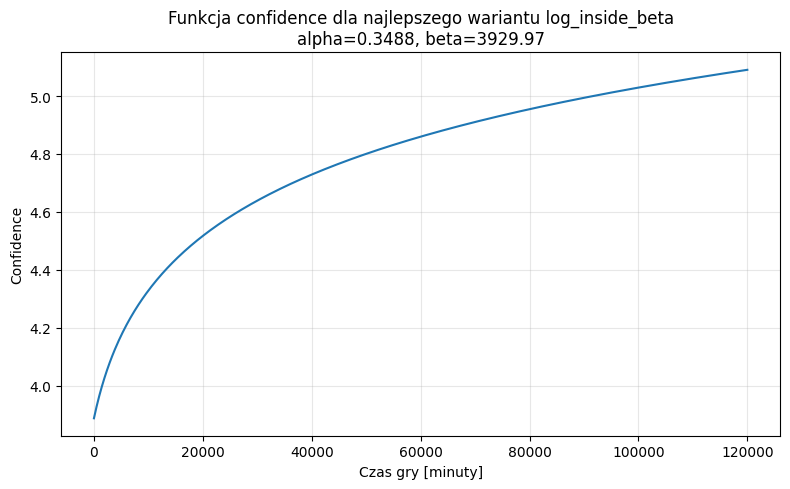

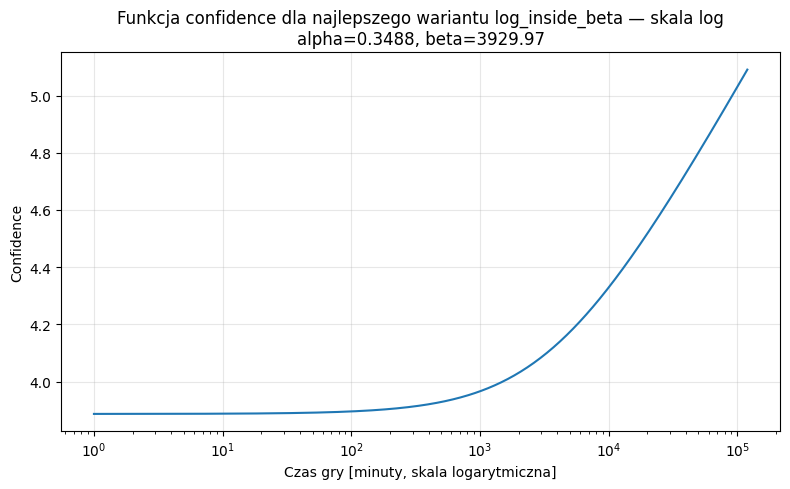

  0%|          | 0/30 [00:00<?, ?it/s]

Model retrained on full dataset

--- TEST SET ---
Users evaluated: 62944
Precision@10:   0.1992
Recall@10:      0.3412
NDCG@10:        0.3567
Coverage@10:    0.1468
Delta GAP@10:   0.3876
Diversity@10:   0.6707


,model,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated,factors,alpha,beta,regularization,iterations
0,log_inside_beta_refined,0.199214,0.341185,0.356682,0.146771,0.387643,0.670706,62944,56,0.348807,3929.973696,0.000198,30


Saved refined test metrics to: D:\Studiowe\Licencjat\modele\final_results\test_metrics_log_inside_beta_refined.csv
Saved refined per-user NDCG to: D:\Studiowe\Licencjat\modele\final_results\per_user_ndcg_log_inside_beta_refined.csv


In [8]:
# =========================
# FINAL TEST — REFINED LOG INSIDE BETA
# using ALSPipeline.refit_full_and_test()
# =========================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Jeśli pipeline nie jest jeszcze zaimportowany w notebooku:
# from steam_recommender.als import ALSPipeline
# from steam_recommender.confidence import make_log_inside_beta_signal

# =========================
# BEST PARAMS FROM REFINED OPTUNA
# =========================

best_log_inside_beta_refined_params = {
    "factors": 56,
    "alpha": 0.348807380860255,
    "beta": 3929.973695903476,
    "regularization": 0.000197617588937398,
    "iterations": 30,
}

best_factors = best_log_inside_beta_refined_params["factors"]
best_alpha = best_log_inside_beta_refined_params["alpha"]
best_beta = best_log_inside_beta_refined_params["beta"]
best_regularization = best_log_inside_beta_refined_params["regularization"]
best_iterations = best_log_inside_beta_refined_params["iterations"]


# =========================
# 1. CONFIDENCE CURVE
# =========================
# c_ui = 1 + alpha * log(1 + playtime + beta)

def confidence_log_inside_beta(playtime, alpha, beta):
    return 1 + alpha * np.log1p(playtime + beta)


playtime_grid = np.linspace(0, 120_000, 500)

confidence_grid = confidence_log_inside_beta(
    playtime_grid,
    alpha=best_alpha,
    beta=best_beta
)

example_playtimes = np.array([
    0,
    10,
    60,
    300,
    1_000,
    5_000,
    10_000,
    30_000,
    60_000,
    120_000
])

confidence_examples_df = pd.DataFrame({
    "playtime_minutes": example_playtimes,
    "playtime_hours": example_playtimes / 60,
    "confidence": confidence_log_inside_beta(
        example_playtimes,
        alpha=best_alpha,
        beta=best_beta
    )
})

display(confidence_examples_df)

print("Best refined params:")
print(best_log_inside_beta_refined_params)

print("\nConfidence range:")
print(
    "c(0) =",
    confidence_log_inside_beta(0, best_alpha, best_beta)
)
print(
    "c(120000) =",
    confidence_log_inside_beta(120_000, best_alpha, best_beta)
)
print(
    "difference =",
    confidence_log_inside_beta(120_000, best_alpha, best_beta)
    - confidence_log_inside_beta(0, best_alpha, best_beta)
)


plt.figure(figsize=(8, 5))
plt.plot(playtime_grid, confidence_grid)
plt.xlabel("Czas gry [minuty]")
plt.ylabel("Confidence")
plt.title(
    "Funkcja confidence dla najlepszego wariantu log_inside_beta\n"
    f"alpha={best_alpha:.4f}, beta={best_beta:.2f}"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


playtime_grid_log = np.logspace(0, np.log10(120_000), 500)

confidence_grid_log = confidence_log_inside_beta(
    playtime_grid_log,
    alpha=best_alpha,
    beta=best_beta
)

plt.figure(figsize=(8, 5))
plt.plot(playtime_grid_log, confidence_grid_log)
plt.xscale("log")
plt.xlabel("Czas gry [minuty, skala logarytmiczna]")
plt.ylabel("Confidence")
plt.title(
    "Funkcja confidence dla najlepszego wariantu log_inside_beta — skala log\n"
    f"alpha={best_alpha:.4f}, beta={best_beta:.2f}"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# =========================
# 2. TRAIN ON FULL TRAIN_VAL AND TEST
# =========================

best_signal_fn = make_log_inside_beta_signal(best_beta)

refined_log_inside_beta_pipeline = ALSPipeline(
    factors=best_factors,
    iterations=best_iterations,
    alpha=best_alpha,
    regularization=best_regularization,
    random_state=0,
    signal_strength_fn=best_signal_fn,
    num_threads=2,
)

refined_results, refined_recommendations, refined_user_ndcg = (
    refined_log_inside_beta_pipeline.refit_full_and_test(
        train_df=train_val_df,
        test_df=test_df,
        K=10,
        return_per_user=True,
        verbose=True,
    )
)


# =========================
# 3. DISPLAY AND SAVE METRICS
# =========================

refined_results_df = pd.DataFrame([{
    "model": "log_inside_beta_refined",
    **refined_results,
    "factors": best_factors,
    "alpha": best_alpha,
    "beta": best_beta,
    "regularization": best_regularization,
    "iterations": best_iterations,
}])

display(refined_results_df)

final_results_dir = str(project_path("results/final"))
os.makedirs(final_results_dir, exist_ok=True)

refined_results_path = os.path.join(
    final_results_dir,
    "test_metrics_log_inside_beta_refined.csv"
)

refined_results_df.to_csv(refined_results_path, index=False)

print(f"Saved refined test metrics to: {refined_results_path}")


# =========================
# 4. SAVE PER-USER NDCG
# =========================

refined_user_ndcg_df = pd.DataFrame({
    "user_id": list(refined_user_ndcg.keys()),
    "ndcg@10": list(refined_user_ndcg.values()),
})

refined_user_ndcg_path = os.path.join(
    final_results_dir,
    "per_user_ndcg_log_inside_beta_refined.csv"
)

refined_user_ndcg_df.to_csv(refined_user_ndcg_path, index=False)

print(f"Saved refined per-user NDCG to: {refined_user_ndcg_path}")